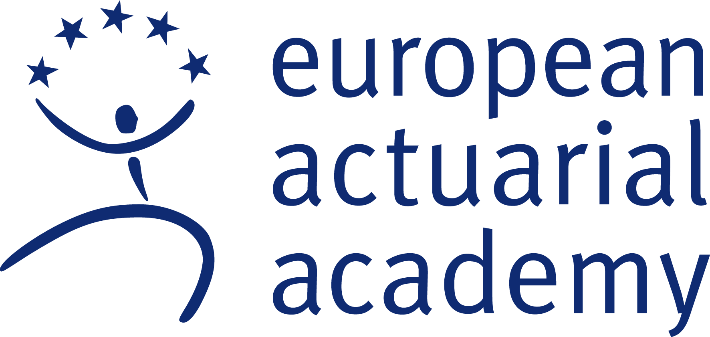

<p style="font-size:17px; text-align:left;"><i>EAA Web Session E0595, GenAI Beyond the Basics: Advanced Concepts for Actuaries, 07 December 2026</i></p>
<p style="font-size:25px; text-align:left; font-weight:bold;">Notebook 2: Structured Outputs, from Free Text to Validated JSON</p>
<p style="font-size:16px; text-align:left; margin-bottom: 15px;">Dr Simon Hatzesberger<br>Programme slot: 09:45–10:05 CET</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonhatzesberger/genai-beyond-the-basics-20261207/blob/main/notebooks/02_structured_outputs.ipynb) &nbsp; Notebook `02_structured_outputs.ipynb` of the repository <https://github.com/simonhatzesberger/genai-beyond-the-basics-20261207>

LLMs write prose; actuarial workflows need **machine-readable data**. This notebook shows how *Structured Outputs*
force a model to answer in a predefined JSON schema, so that the result drops straight into code, spreadsheets and
databases. The use case extracts policy data from synthetic motor insurance contracts in three increasingly strict
stages, checks the result in code, and finally turns ten contracts into a portfolio table.

**Contents**
1. [Concept and purpose](#structured-outputs-concept)
2. [Setup](#setup)
3. [Use case: structured data extraction from policy documents](#structured-outputs-usecase)
4. [Further applications and resources](#structured-outputs-further-applications-and-resources)

<h1 id="structured-outputs-concept"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
1. Concept and Purpose
</h1>

LLMs are designed to produce human-readable prose, yet many actuarial workflows require **machine-readable data** that drops straight into code, spreadsheets, or databases. The concept of *Structured Outputs* solves this by enforcing the model to return a response that follows a **predefined JSON schema** rather than free-form text. When the LLM reliably fills named fields with well-specified data types, the result can be parsed deterministically – removing the need for fragile regex parsers and ad-hoc clean-up scripts.

<div style="background-color: #f2f2f2; border-left: 4px solid #888888; padding-left: 10px; padding-bottom: 1px; padding-top: 6px;">
<p style="font-weight: bold"><b>Note</b></p>
<p style="margin-bottom: 10px;">
In OpenAI's Responses API, Structured Outputs are applied with <code>client.responses.parse(..., text_format=YourPydanticModel)</code>; the validated object is returned in <code>response.output_parsed</code>. Combined with <i>Pydantic</i> (or a comparable schema library), it ensures end-to-end adherence to your JSON schema. The same workflow applies to other providers: declare the schema, embed its definition in the prompt, and instruct the model to honour it.
</p>
</div>

#### Why It Matters for Actuaries  

* **Repeatability** – pricing, reserving, and reporting pipelines receive the same field names and formats every run.  
* **Interoperability** – JSON can be consumed by spreadsheets, BI dashboards, or actuarial software (e.g., Prophet, ResQ) with no extra transformation layer.  
* **Expressiveness** – nested objects and optional fields capture complex insurance concepts such as multi-vehicle policies, layered treaties, or cash-flow waterfalls.

#### How Structured Outputs Work

1. **Define the schema**: create a *Pydantic* model (or a JSON schema) that describes the desired output, with types,
   allowed values (`Literal`), optional fields and nesting.
2. **Send prompt + schema**: pass the class as `text_format`. The API converts it into a strict JSON schema.
3. **Constrained generation**: the model can only produce output that conforms to the schema (*constrained
   decoding*), so field names and types are guaranteed. The *content* of the fields can still be wrong.
4. **Parse, check and use**: your code receives a validated Python object, checks what can be checked
   (plausibility, totals, dates) and feeds it into downstream processes.

<h1 id="setup"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
2. Setup
</h1>

In [1]:
# ── Setup: run this cell first ───────────────────────────────────────────────────────────────
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_RAW = "https://raw.githubusercontent.com/simonhatzesberger/genai-beyond-the-basics-20261207/main/notebooks/"

import json
from concurrent.futures import ThreadPoolExecutor
from datetime import date
from typing import List, Literal, Optional

import pandas as pd
from pydantic import BaseModel, Field
from openai import OpenAI


def load_openai_api_key(name: str = "OPENAI_API_KEY", file_path: str = "openai_api_key.txt") -> str | None:
    """Look for the key in Colab Secrets, then in an environment variable, then in a local text file."""
    try:
        from google.colab import userdata  # only available in Colab
        value = userdata.get(name)
        if value:
            return value.strip()
    except Exception:
        pass
    if os.getenv(name):
        return os.getenv(name).strip()
    for candidate in (Path(file_path), Path("..") / file_path):
        if candidate.exists():
            return candidate.read_text(encoding="utf-8").strip()
    return None


api_key = load_openai_api_key()
client = OpenAI(api_key=api_key or "no-key-found")   # the key's value is never printed

MODEL = "gpt-6-luna"           # OpenAI's current small model (checked 22 Nov 2026: no announced shutdown date)
REASONING = {"effort": "low"}  # always set the reasoning effort explicitly (the default is "medium")


def data_file(name: str) -> Path:
    """A data file of this notebook: from data/ next to it, otherwise downloaded once from GitHub (e.g. in Colab)."""
    path = Path("data") / name
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + "data/" + name, path)
        print(f"Downloaded data/{name} from GitHub.")
    return path

print("Running in", "Google Colab" if IN_COLAB else "a local Python " + sys.version.split()[0])
print("OpenAI API key:", "found" if api_key else "NOT found - you can read the saved outputs, but API calls will fail "
      "(see 00_setup_check.ipynb)")
print("Model:", MODEL, "| reasoning effort:", REASONING["effort"])

Running in a local Python 3.13.1
OpenAI API key: found
Model: gpt-6-luna | reasoning effort: low


<h1 id="structured-outputs-usecase"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
3. Use Case: Structured Data Extraction from Policy Documents
</h1>

In this use case we ask an LLM to analyse a **synthetic automobile insurance policy** from the open-access [RISCBAC corpus](https://huggingface.co/datasets/davebulaval/RISCBAC) — a dataset of 10 000 bilingual (FR/EN) contracts generated from the Québec standard form.

A RISCBAC auto policy embeds a variety of structured facts that we extract in this notebook, for example:

* Policy and endorsement numbers  
* Insured's personal details (name, address, date of birth)  
* Vehicle information (VIN, make, model, year)  
* Coverage sections with limits and deductibles  
* Premium amounts by coverage type  
* Policy effective and expiry dates  

Our task is to extract specified data fields from the narrative policy and format them as a **machine-readable JSON object**, which in a real-world workflow could then be consumed by downstream code.

A whole RISCBAC contract runs to about 160,000 characters (some 34,000 tokens). Everything we need is on its
**declarations pages**, so we cut each contract to those pages before sending it: from the page header that names the
form and the policy number, up to the privacy notice that starts at `DISCLOSURE`. This saves about 97% of the tokens,
keeps irrelevant amounts out of the model's view, and makes the answer easy to check by hand.

In [2]:
contracts = [json.loads(line)["text"] for line in
             data_file("riscbac_en_first10.jsonl").read_text(encoding="utf-8").splitlines()]


def declarations(text: str) -> str:
    """The declarations pages of a RISCBAC contract (from the form header before 'DECLARATIONS' to 'DISCLOSURE')."""
    start = text.rindex("QUEBEC AUTOMOBILE INSURANCE POLICY", 0, text.index("DECLARATIONS"))
    return text[start:text.index("DISCLOSURE", start)]


policy_texts = [declarations(t) for t in contracts]
text_content = policy_texts[0]   # the contract used in stages 1 to 3

print(f"{len(contracts)} contracts; full length {len(contracts[0]):,} characters, declarations {len(text_content):,} characters.\n")
print(text_content[:3500])
print("\n[... first 3,500 characters shown ...]")

10 contracts; full length 160,191 characters, declarations 4,751 characters.

QUEBEC AUTOMOBILE INSURANCE POLICY
Q.P.F. B 1 - OWNER'S FORM
Policy Number: 382787-001

DECLARATIONS
ISSUE of your new insurance policy
Item 1. NAME AND ADDRESS OF THE NAMED INSURED*
Ryan Craig
6722 Kim Hollow Suite 899
Shirleyburgh, NL B6E 2C9
*The described vehicle is and will be mainly used, stored and parked in the town/city and province shown in Item 1. If not, the client or the named insured must so declare.
Item 2. CONTRACT PERIOD
FROM: 2022-12-25* TO: 2023-12-25* EXCLUSIVELY
*at 12:01 A.M. standard time at the address of the named insured.
Item 3. PARTICULARS OF THE DESCRIBED VEHICLE 1
Acura - RDX - 2010 - Numéro de série UE4SMUNYHL50SETQ0 - Purchase used
Creditor entitled to Chapter B benefits, according to his interest - Subject to the Q.E.F. endorsement N 23a
National Bank of Canada 366 Lee Canyon
South Richardton, BC E8G 8M6
Item 4. COVERAGE / PERILS: The perils covered by the insurance contract a

We structure this exercise in three progressively stricter stages:

1. **Stage 1 — Free-form extraction**  
   Prompt the model without a schema and observe the variability.  
2. **Stage 2 — Basic flat schema**  
   Supply a minimal Pydantic model to stabilise output.  
3. **Stage 3 — Advanced nested schema**  
   Use a comprehensive Pydantic hierarchy to capture full policy complexity.

### Stage 1 — Free-form extraction

In this first experiment, we ask the model to pull the driver’s last and first names, vehicle details, premium amount, and contract period without any formal schema. Run the cell multiple times and you may notice:

* Thousands separators may appear or vanish.  
* Currency symbols can be included or omitted.  
* Sometimes the output is formatted as bullet points and other times as free-form text.    

Although each response is human-readable, the format is too inconsistent for reliable downstream parsing.

Note that in all approaches, the extraction prompt goes into the `instructions` parameter, while the policy text to be analysed is passed via the `input` parameter.

In [3]:
instructions_car_insurance_naive = """
You will be given a free-form description of a car insurance contract.
Your job is to extract the driver's last name, the driver's first name, the vehicle, the premium, and the contract period.
"""

contract_information_naive = client.responses.create(
    model=MODEL,
    reasoning=REASONING,
    instructions=instructions_car_insurance_naive,
    input=text_content,
)
print(contract_information_naive.output_text)

- **Driver’s last name:** Craig
- **Driver’s first name:** Ryan
- **Vehicle:** 2010 Acura RDX
- **Premium:** $1,047 annually, excluding tax
- **Contract period:** December 25, 2022 – December 25, 2023


#### Stage 2 — Basic flat schema  
Next, we define a simple Pydantic model `CarInsuranceContract_basic` listing only the required fields—each with an explicit type (string or integer). By setting `text_format=CarInsuranceContract_basic`, the underlying LLM is instructed to return a strictly valid JSON object that conforms to this schema. The result is now fully deterministic and ready for parsing, with (usually) identical output across repeated runs and no ad-hoc cleanup needed.

In [4]:
# 1. Define the class for the Structured Output
class CarInsuranceContract_basic(BaseModel):
    driver_last_name: str
    driver_first_name: str
    vehicle_make_and_model: str
    premium: int
    contract_period: str

# 2. Craft a precise instruction for the schema
instructions_car_insurance_basic = """
You will be given a free-form description of a car insurance contract.
Extract the driver's names, the vehicle (make, model and year), the annual premium before tax as an integer,
and the contract period.
"""

# 3. Call the LLM with text_format=CarInsuranceContract_basic
contract_information_basic = client.responses.parse(
    model=MODEL,
    reasoning=REASONING,
    instructions=instructions_car_insurance_basic,
    input=text_content,
    text_format=CarInsuranceContract_basic,
)

# 4. Display the resulting (JSON) output
print(json.dumps(contract_information_basic.output_parsed.model_dump(), indent=2))

{
  "driver_last_name": "Craig",
  "driver_first_name": "Ryan",
  "vehicle_make_and_model": "2010 Acura RDX",
  "premium": 1047,
  "contract_period": "2022-12-25 to 2023-12-25"
}


#### Stage 3 — Advanced nested schema

Finally, we define a richer Pydantic hierarchy `CarInsuranceContract_advanced` that mirrors real-world policy
complexity with several nesting levels and stricter typing:

* **Driver**: `last_name`, `first_name`, an *optional* `second_first_name`, and a `birth_date` of type `date`.
* **Vehicle**: `make_and_model`, `model_year` and `serial_number`.
* **Contract**: `start_date` and `end_date` as dates, and an enum-constrained `currency`.
* **Premium**: `premium_before_tax`, `tax`, and the list of protections under *Section B – Damage to insured vehicles*.

`Field(description=...)` documents each field for the model, so the schema itself carries most of the instruction.

In [5]:
# 1. Define the classes for the Structured Output
class Driver(BaseModel):
    last_name: str
    first_name: str
    second_first_name: Optional[str] = Field(None, description="Only if a second first name is stated, else null")
    birth_date: date

class Vehicle(BaseModel):
    make_and_model: str = Field(description="Make and model without the year, e.g. 'Acura RDX'")
    model_year: int
    serial_number: str

class Contract(BaseModel):
    start_date: date
    end_date: date
    currency: Literal["CAD", "USD", "EUR", "other"]

class Premium(BaseModel):
    premium_before_tax: float
    tax: float
    damage_to_insured_vehicles: List[str] = Field(
        description="The protections listed under 'Section B - Damage to insured vehicles', exactly as stated")

class CarInsuranceContract_advanced(BaseModel):
    driver: Driver
    vehicle: Vehicle
    contract: Contract
    premium: Premium

# 2. A short instruction is enough: the schema carries the details
instructions_car_insurance_advanced = """
You will be given the declarations pages of a car insurance contract.
Extract the requested fields. Use only information stated in the text; amounts are numbers without currency symbols.
"""

# 3. Call the model with text_format=CarInsuranceContract_advanced
contract_information_advanced = client.responses.parse(
    model=MODEL,
    reasoning=REASONING,
    instructions=instructions_car_insurance_advanced,
    input=text_content,
    text_format=CarInsuranceContract_advanced,
)
contract = contract_information_advanced.output_parsed

# 4. Inspect the resulting (JSON) output
print(contract.model_dump_json(indent=2))

{
  "driver": {
    "last_name": "Craig",
    "first_name": "Ryan",
    "second_first_name": null,
    "birth_date": "1984-07-27"
  },
  "vehicle": {
    "make_and_model": "Acura RDX",
    "model_year": 2010,
    "serial_number": "UE4SMUNYHL50SETQ0"
  },
  "contract": {
    "start_date": "2022-12-25",
    "end_date": "2023-12-25",
    "currency": "CAD"
  },
  "premium": {
    "premium_before_tax": 1047.0,
    "tax": 94.22999999999999,
    "damage_to_insured_vehicles": [
      "Protection 1: All risks Included",
      "Protection 2: Risk of collision and rollover - Deductible 1000$ per claim 380$",
      "Protection 3: All risks except collision or rollover - Deductible 500$ per claim 202$",
      "Protection 4: Specific risks Included"
    ]
  }
}


#### What code can check

The schema guarantees **form**: every field is present and has the right type, and a `date` is a real date. It does
not guarantee **content**. Because the answer is now a Python object, code can check what is checkable, cheaply and
on every single call:

In [6]:
c = contract
checks = {
    "contract runs 12 months":       (c.contract.end_date - c.contract.start_date).days in (365, 366),
    "premium is positive":           c.premium.premium_before_tax > 0,
    "tax between 0% and 15%":        0 <= c.premium.tax <= 0.15 * c.premium.premium_before_tax,
    "driver at least 16 at start":   (c.contract.start_date - c.driver.birth_date).days / 365.25 >= 16,
    "VIN has 17 characters":         len(c.vehicle.serial_number) == 17,
    "premium appears in the text":   f"{c.premium.premium_before_tax:g}" in text_content.replace(",", ""),
}
for name, ok in checks.items():
    print(f"[{'PASS' if ok else 'CHECK'}] {name}")

[PASS] contract runs 12 months
[PASS] premium is positive
[PASS] tax between 0% and 15%
[PASS] driver at least 16 at start
[PASS] VIN has 17 characters
[PASS] premium appears in the text


A `CHECK` is not necessarily a model error: the RISCBAC contracts are synthetic and contain generator artefacts
(for example implausible driver ages or taxes printed with floating-point noise). That is exactly why the checks
belong in code, where every exception is visible, rather than in a person's memory.

#### From ten contracts to a portfolio table

The same schema and instruction now run over all ten contracts. Because API calls are independent, we send them
**in parallel**, which is one of the practical advantages of API access over a chat window.

In [7]:
def extract(policy_text: str) -> CarInsuranceContract_advanced:
    r = client.responses.parse(
        model=MODEL, reasoning=REASONING,
        instructions=instructions_car_insurance_advanced, input=policy_text,
        text_format=CarInsuranceContract_advanced,
    )
    return r.output_parsed

with ThreadPoolExecutor(max_workers=5) as pool:
    portfolio = list(pool.map(extract, policy_texts))

table = pd.DataFrame([{
    "driver": f"{p.driver.first_name} {p.driver.last_name}",
    "born": p.driver.birth_date,
    "vehicle": f"{p.vehicle.make_and_model} {p.vehicle.model_year}",
    "start": p.contract.start_date,
    "premium": p.premium.premium_before_tax,
    "tax": p.premium.tax,
    "section B covers": len(p.premium.damage_to_insured_vehicles),
} for p in portfolio])
table

,driver,born,vehicle,start,premium,tax,section B covers
0,Ryan Craig,1984-07-27,Acura RDX 2010,2022-12-25,1047.0,94.23,4
1,Kevin Parrish,2006-10-06,Genesis G90 2017,2022-06-14,1035.0,93.15,4
2,Janice Garner,1940-07-11,Subaru Outback 2001,2022-11-29,911.0,81.99,4
3,Bryan Clark,1962-02-27,Mercedes-Benz M-Class 2003,2022-09-10,721.0,64.89,4
4,Elizabeth Williams,1955-05-09,Mercedes-Benz GLS 2020,2022-02-18,901.0,81.09,4
5,Felicia Weber,1964-12-30,Chevrolet Silverado 2500 Extended Cab 2003,2022-04-23,952.0,85.68,4
6,William Green,1941-02-17,Oldsmobile 98 1995,2022-06-18,1061.0,95.49,4
7,Patrick Munoz,1947-08-01,BMW X6 2017,2022-11-10,1204.0,108.36,4
8,Christine Smith,1971-03-19,Ford Club Wagon 1998,2022-11-28,954.0,85.86,4
9,James Kim,1948-05-28,Kia Spectra 2007,2022-04-10,1057.0,95.13,4


Ten contracts became one table in a few seconds, with identical column names and types on every row. The same
code runs unchanged over ten thousand contracts; at that point, sampling rows for human review and logging every
call become part of the process.

<h1 id="structured-outputs-further-applications-and-resources"
    style="font-size:22px; background-color:#E6E6E6; color:black;
           height:50px; line-height:50px; padding-left:14px;">
4. Further Applications and Resources
</h1>

#### Additional Actuarial Applications for Structured Outputs

* **Multiclass classification** – Structured Outputs enforce predefined classes when categorising document types, car damage types from images, or claim severity levels, ensuring consistent and error-free data for downstream processes.
* **Fraud detection and pattern recognition** – Transforming narrative data from customer interactions, adjuster observations, and historical claim patterns into structured datasets to efficiently feed machine learning models for detecting anomalies and fraud risks.
* **Claims settlement automation** – Extracting structured information from claim adjuster notes and communications to automate payments, reserving, and auditing workflows, significantly reducing manual interventions and errors.

#### Further Reading and Resources on Structured Outputs

1. [Structured model outputs — OpenAI API Guide](https://developers.openai.com/api/docs/guides/structured-outputs)
    * *Type:* Official Documentation
    * *Summary:* Current reference for `json_schema` strict mode via the Responses API — guarantees parseable, schema-conformant JSON for actuarial pipelines.
2. [Introducing Structured Outputs in the API — OpenAI](https://openai.com/index/introducing-structured-outputs-in-the-api/)
    * *Type:* Official Blog Announcement
    * *Summary:* Background on schema-guaranteed outputs and why they remove brittle post-processing.
3. [Introduction to Structured Outputs — OpenAI Cookbook](https://cookbook.openai.com/examples/structured_outputs_intro)
    * *Type:* Cookbook Notebook
    * *Summary:* Hands-on walk-through enforcing a Pydantic schema and measuring failure rates.